# Project 09: Permutation Importance vs Built-in Importance
## An Adult Income study
**Name:** B.Vishnutharan  
**Registration number:** 2021/ICT/106

**Project question:** How do Random Forest's built-in feature importance and permutation importance differ when predicting adult income, and when can their rankings be misleading?

I chose this question before loading the data. The aim is to check how much trust to place in a model's feature rankings.

Run the cells from top to bottom. The saved outputs cover data checks, model comparisons, and final test evaluation. Importance experiments and error reviews follow in later commits. Charts and result tables for this stage are saved in `figures/` and `results/`.

## 1. Plan and data choice
I chose the public UCI Adult Income dataset because it contains both numbers and categories. It has 48,842 rows and 14 input columns before cleaning. The target is whether a person's annual income was above $50,000. The data comes from the 1994 US Census, so it does not describe present-day income in Sri Lanka.

The work follows these steps:
1. Check and clean the data.
2. Keep the original test file separate.
3. Compare a majority-class baseline, Logistic Regression, and Random Forest using training data.
4. Select Random Forest settings using cross-validation.
5. Measure final results on the test set.
6. Compare importance methods and run a separate random-column experiment.
7. Review at least 10 wrong predictions and explain the limits.

**Source:** [UCI Adult dataset](https://archive.ics.uci.edu/dataset/2/adult). Becker, B. and Kohavi, R. (1996), DOI: 10.24432/C5XW20. License: CC BY 4.0.

## 2. Set up the project
The seed fixes random choices so the results can be repeated. A pipeline keeps data preparation and model fitting together. Each validation fold learns its own preparation steps from its training rows.

The notebook works from the project folder and uses local data files. It does not need an online account or an API key.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, GroupShuffleSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score, average_precision_score,
                            confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                            PrecisionRecallDisplay, classification_report)

ROOT = Path.cwd()
assert (ROOT / 'data/raw/adult.data').exists(), 'Open this notebook from the project folder.'
for folder in ['results', 'figures']:
    (ROOT / folder).mkdir(exist_ok=True)
SEED = 106
REPEATS = 10
PERM_ROWS = 2500
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'savefig.bbox': 'tight'})

def save_chart(name):
    plt.savefig(ROOT / 'figures' / f'{name}.png', dpi=160)
    plt.show()
    plt.close()

print('Python:', platform.python_version())
print('Random seed:', SEED)

Python: 3.13.2
Random seed: 106


## 3. Load the original files
`adult.data` is the supplied training file. `adult.test` is the supplied test file. A question mark means a missing value. Some test labels end with a full stop, which needs to be removed.

The file checks below help confirm that the same source files are used in another run.

In [2]:
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
           'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
           'hours-per-week', 'native-country', 'income']
features = columns[:-1]
numeric = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
categorical = [c for c in features if c not in numeric]

def read_adult(filename):
    frame = pd.read_csv(ROOT / 'data/raw' / filename, names=columns,
                        skipinitialspace=True, na_values='?', comment='|')
    for col in frame.select_dtypes(include=['object', 'string']).columns:
        frame[col] = frame[col].str.strip()
    frame['income'] = frame['income'].str.rstrip('.')
    assert set(frame['income'].dropna()) == {'<=50K', '>50K'}
    return frame

raw_train = read_adult('adult.data')
raw_test = read_adult('adult.test')
checksums = {name: hashlib.sha256((ROOT / 'data/raw' / name).read_bytes()).hexdigest()
             for name in ['adult.data', 'adult.test', 'adult.names']}
(ROOT / 'results/source_checksums.json').write_text(json.dumps(checksums, indent=2))
print('Original training rows:', len(raw_train))
print('Original test rows:', len(raw_test))
assert len(raw_train) + len(raw_test) == 48842
display(raw_train.head())

Original training rows: 32561
Original test rows: 16281


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## 4. Data checks and repeated records
I checked missing values, repeated rows, and repeated input profiles because these can affect the result.

An input profile means all 14 input values together. Exact repeated rows are kept once in each file. Any test profile already present in training is removed from the test set. This makes the test stricter, but it also means the final score applies to a cleaned test set rather than the full original test file.

If two training rows have the same input profile, they stay in the same cross-validation fold. This also covers the rare case where the same inputs have different income labels.

In [3]:
train = raw_train.drop_duplicates().copy()
test_unique = raw_test.drop_duplicates().copy()
train_profiles = pd.util.hash_pandas_object(train[features], index=False)
test_profiles = pd.util.hash_pandas_object(test_unique[features], index=False)
overlap = test_profiles.isin(set(train_profiles))
test = test_unique.loc[~overlap].copy()

audit = {'raw_train_rows': len(raw_train), 'raw_test_rows': len(raw_test),
         'train_exact_duplicates_removed': len(raw_train) - len(train),
         'test_exact_duplicates_removed': len(raw_test) - len(test_unique),
         'overlapping_test_profiles_removed': int(overlap.sum()),
         'clean_train_rows': len(train), 'clean_test_rows': len(test)}
display(pd.Series(audit, name='Rows').to_frame())
missing = train[features].isna().sum().sort_values(ascending=False)
display(missing.rename('Missing training values').to_frame())
assert not set(pd.util.hash_pandas_object(test[features], index=False)) & set(train_profiles)
assert train[numeric].notna().all().all()
assert train['age'].between(17, 100).all()
assert train['hours-per-week'].between(1, 99).all()

train.to_csv(ROOT / 'data/adult_train_clean.csv', index=False)
test.to_csv(ROOT / 'data/adult_test_clean.csv', index=False)
pd.Series(audit).to_csv(ROOT / 'results/data_audit.csv', header=['rows'])
X_train, y_train = train[features].copy(), train['income'].eq('>50K').astype(int)
X_test, y_test = test[features].copy(), test['income'].eq('>50K').astype(int)
groups = pd.util.hash_pandas_object(X_train, index=False).to_numpy()

,Rows
raw_train_rows,32561
raw_test_rows,16281
train_exact_duplicates_removed,24
test_exact_duplicates_removed,5
overlapping_test_profiles_removed,26
clean_train_rows,32537
clean_test_rows,16250


,Missing training values
occupation,1843
workclass,1836
native-country,582
education,0
fnlwgt,0
age,0
marital-status,0
education-num,0
race,0
relationship,0


## 5. Understand the training data
These charts use training data only. The income classes are not equal in size, so accuracy alone can hide poor results for the smaller class.

Some column meanings:
- `education-num`: education level stored as a number. It is closely linked to `education`.
- `fnlwgt`: a Census sample weight. It is kept as an input for this importance study, not used as a row weight. All evaluation scores treat each row equally.
- `capital-gain` and `capital-loss`: recorded gains and losses.
- `hours-per-week`: reported working hours each week.
- `sex` and `race`: historical categories from the source. Their use needs care because the data can reflect unfair differences.

The original source guide, `data/raw/adult.names`, describes all columns.

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,32537.00,32537.00,32537.00,32537.00,32537.00,32537.00
mean,38.59,189780.85,10.08,1078.44,87.37,40.44
std,13.64,105556.47,2.57,7387.96,403.10,12.35
min,17.00,12285.00,1.00,0.00,0.00,1.00
25%,28.00,117827.00,9.00,0.00,0.00,40.00
50%,37.00,178356.00,10.00,0.00,0.00,40.00
75%,48.00,236993.00,12.00,0.00,0.00,45.00
max,90.00,1484705.00,16.00,99999.00,4356.00,99.00


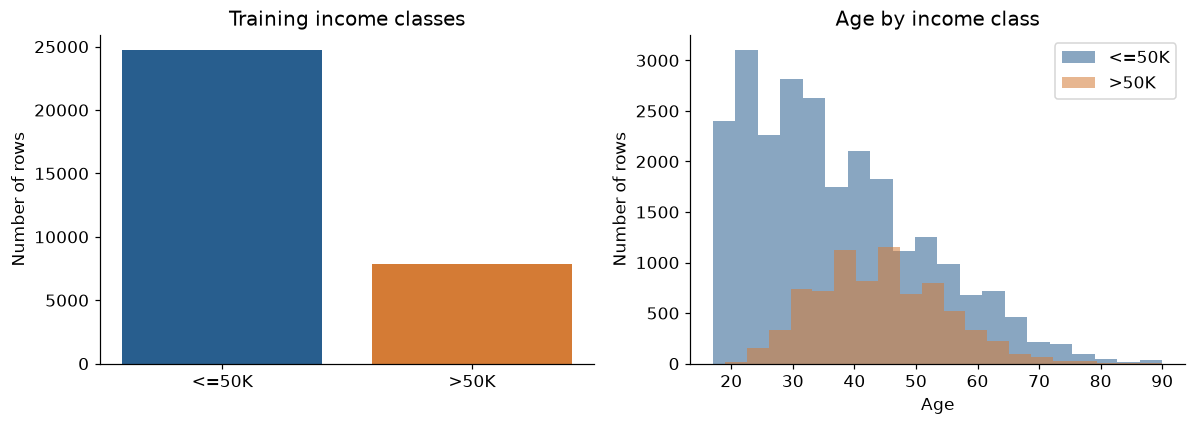

,Distinct categories
workclass,8
education,16
marital-status,7
occupation,14
relationship,6
race,5
sex,2
native-country,41


The majority-class baseline can reach 75.9% training accuracy without learning any income patterns.


In [4]:
display(train[numeric].describe().round(2))
class_counts = y_train.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(['<=50K', '>50K'], class_counts, color=['#285E8E', '#D47B35'])
axes[0].set(title='Training income classes', ylabel='Number of rows')
for label, colour in [(0, '#285E8E'), (1, '#D47B35')]:
    axes[1].hist(X_train.loc[y_train == label, 'age'], bins=20, alpha=.55,
                 label=['<=50K', '>50K'][label], color=colour)
axes[1].set(title='Age by income class', xlabel='Age', ylabel='Number of rows')
axes[1].legend()
fig.tight_layout()
save_chart('01_training_data')

category_counts = X_train[categorical].nunique().rename('Distinct categories')
display(category_counts.to_frame())
print(f'The majority-class baseline can reach {class_counts.max()/class_counts.sum():.1%} training accuracy without learning any income patterns.')

## 6. Prepare the inputs safely
Missing numbers use the training median. Missing categories use the most common training value. One-hot encoding creates a separate 0/1 column for each category. Unknown categories in later data are accepted.

Logistic Regression also scales numbers so a column with large values does not dominate its fitting process. Trees do not need scaling.

These steps sit inside each model pipeline. They are fitted again inside every cross-validation fold. Test rows never teach the preparation steps.

In [5]:
def make_preprocessor(scale=False, extra_numeric=None, extra_categorical=None):
    num_cols = numeric + (extra_numeric or [])
    cat_cols = categorical + (extra_categorical or [])
    num_steps = [('fill', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(num_steps), num_cols),
        ('cat', Pipeline([('fill', SimpleImputer(strategy='most_frequent')),
                          ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols)
    ], sparse_threshold=0)

def make_forest(leaf, extra_numeric=None, extra_categorical=None):
    return Pipeline([
        ('prepare', make_preprocessor(False, extra_numeric, extra_categorical)),
        ('model', RandomForestClassifier(n_estimators=120, min_samples_leaf=leaf,
                                         max_features=.7, n_jobs=2, random_state=SEED))
    ])

models = {
    'Majority baseline': Pipeline([('prepare', make_preprocessor()),
                                  ('model', DummyClassifier(strategy='most_frequent'))]),
    'Logistic Regression': Pipeline([('prepare', make_preprocessor(scale=True)),
                                    ('model', LogisticRegression(max_iter=2000, C=1, random_state=SEED))]),
    'Random Forest leaf 1': make_forest(1),
    'Random Forest leaf 5': make_forest(5),
    'Random Forest leaf 15': make_forest(15)
}

## 7. Cross-validation and model choice
Five folds give five checks on rows left out of fitting. Stratification keeps the income mix similar across folds. Grouping keeps matching input profiles together.

**Selection rule fixed before testing:** choose the Random Forest with the highest mean cross-validation ROC-AUC. ROC-AUC measures how well the model ranks the two classes across score thresholds. The final prediction threshold stays at 0.5. The same folds are used for all models.

The majority baseline is the simplest comparison. Logistic Regression is a stronger, simple model. Random Forest remains the main model because this project studies tree importance. No setting will change after the test results are seen.

In [6]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
splits = list(cv.split(X_train, y_train, groups=groups))
for fit_idx, valid_idx in splits:
    assert not set(groups[fit_idx]) & set(groups[valid_idx])

scoring = {'roc_auc': 'roc_auc', 'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'accuracy': 'accuracy'}
cv_rows, fold_rows = [], []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=splits, scoring=scoring,
                            n_jobs=1, error_score='raise')
    row = {'model': name}
    for metric in scoring:
        row[f'{metric}_mean'] = float(scores[f'test_{metric}'].mean())
        row[f'{metric}_std'] = float(scores[f'test_{metric}'].std(ddof=1))
    cv_rows.append(row)
    for i in range(5):
        fold_rows.append({'model': name, 'fold': i+1,
                          **{metric: float(scores[f'test_{metric}'][i]) for metric in scoring}})
    print(name, 'mean ROC-AUC:', round(row['roc_auc_mean'], 4), flush=True)

cv_results = pd.DataFrame(cv_rows).set_index('model')
display(cv_results.round(4))
cv_results.to_csv(ROOT / 'results/cross_validation.csv')
pd.DataFrame(fold_rows).to_csv(ROOT / 'results/cross_validation_folds.csv', index=False)
forest_scores = cv_results.loc[cv_results.index.str.startswith('Random Forest')]
selected_name = forest_scores['roc_auc_mean'].idxmax()
print('Selected tree model:', selected_name)

Majority baseline mean ROC-AUC: 0.5


Logistic Regression mean ROC-AUC: 0.9057


Random Forest leaf 1 mean ROC-AUC: 0.9051


Random Forest leaf 5 mean ROC-AUC: 0.9139


Random Forest leaf 15 mean ROC-AUC: 0.9159


,roc_auc_mean,roc_auc_std,balanced_accuracy_mean,balanced_accuracy_std,f1_mean,f1_std,accuracy_mean,accuracy_std
model,,,,,,,,
Majority baseline,0.5000,0.0000,0.5000,0.0000,0.0000,0.0000,0.7591,0.0001
Logistic Regression,0.9057,0.0054,0.7635,0.0111,0.6574,0.0164,0.8506,0.0053
Random Forest leaf 1,0.9051,0.0039,0.7761,0.0082,0.6749,0.0126,0.8554,0.0052
Random Forest leaf 5,0.9139,0.0041,0.7796,0.0065,0.6844,0.0100,0.8622,0.0038
Random Forest leaf 15,0.9159,0.0043,0.7770,0.0081,0.6814,0.0124,0.8620,0.0045


Selected tree model: Random Forest leaf 15


## 8. Final test results
The chosen forest and both baselines now fit all cleaned training rows. The test file is used only after the settings have been fixed.

Metric meanings:
- **Accuracy:** share of all predictions that are correct.
- **Balanced accuracy:** average recall of the two income classes.
- **Precision:** among predicted >50K rows, the share that are correct.
- **Recall:** among actual >50K rows, the share found by the model.
- **F1:** a combined measure of precision and recall.
- **ROC-AUC:** how well probability scores rank the two classes.
- **Average precision:** a summary of the precision-recall curve, useful for unequal classes.

Class 1 means >50K. A probability of at least 0.5 gives class 1.

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
model,,,,,,,
Majority baseline,0.7637,0.5000,0.0000,0.0000,0.0000,0.5000,0.2363
Logistic Regression,0.8506,0.7596,0.7280,0.5870,0.6499,0.9038,0.7594
Random Forest leaf 15,0.8625,0.7762,0.7592,0.6125,0.6780,0.9133,0.7994


Training accuracy: 0.8863. Test accuracy: 0.8625. Gap: 0.0238.
              precision    recall  f1-score   support

       <=50K       0.89      0.94      0.91     12410
        >50K       0.76      0.61      0.68      3840

    accuracy                           0.86     16250
   macro avg       0.82      0.78      0.80     16250
weighted avg       0.86      0.86      0.86     16250

The forest changes test accuracy by +9.88 percentage points compared with the majority baseline.
Its ROC-AUC difference from Logistic Regression is +0.0095. This is an observed difference, not a significance test.


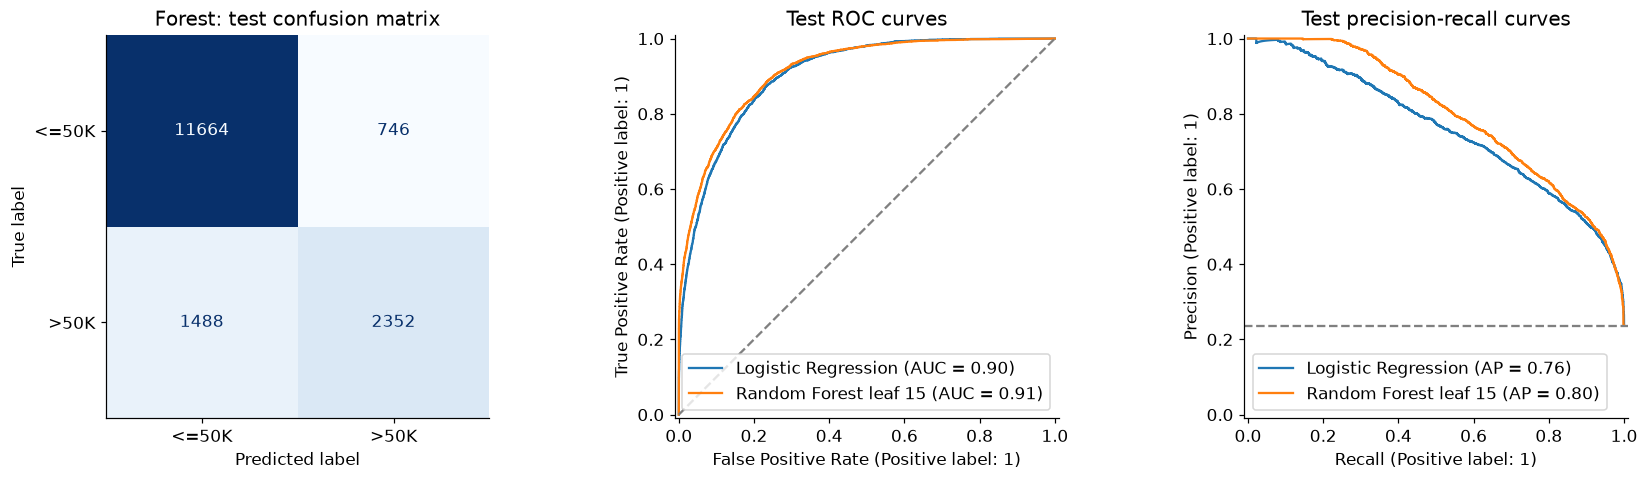

In [7]:
def evaluate(model, X, y):
    probability = model.predict_proba(X)[:, 1]
    prediction = (probability >= .5).astype(int)
    return {'accuracy': accuracy_score(y, prediction),
            'balanced_accuracy': balanced_accuracy_score(y, prediction),
            'precision': precision_score(y, prediction, zero_division=0),
            'recall': recall_score(y, prediction, zero_division=0),
            'f1': f1_score(y, prediction, zero_division=0),
            'roc_auc': roc_auc_score(y, probability),
            'average_precision': average_precision_score(y, probability)}

fitted = {}
test_rows = []
for name in ['Majority baseline', 'Logistic Regression', selected_name]:
    fitted[name] = clone(models[name]).fit(X_train, y_train)
    test_rows.append({'model': name, **evaluate(fitted[name], X_test, y_test)})
test_results = pd.DataFrame(test_rows).set_index('model')
display(test_results.round(4))
test_results.to_csv(ROOT / 'results/test_metrics.csv')
forest = fitted[selected_name]
test_probability = forest.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= .5).astype(int)
train_metrics = evaluate(forest, X_train, y_train)
gap = train_metrics['accuracy'] - test_results.loc[selected_name, 'accuracy']
print(f'Training accuracy: {train_metrics["accuracy"]:.4f}. Test accuracy: {test_results.loc[selected_name, "accuracy"]:.4f}. Gap: {gap:.4f}.')
print(classification_report(y_test, test_prediction, target_names=['<=50K', '>50K'], zero_division=0))
baseline_gain = test_results.loc[selected_name, 'accuracy'] - test_results.loc['Majority baseline', 'accuracy']
logistic_gain = test_results.loc[selected_name, 'roc_auc'] - test_results.loc['Logistic Regression', 'roc_auc']
print(f'The forest changes test accuracy by {baseline_gain*100:+.2f} percentage points compared with the majority baseline.')
print(f'Its ROC-AUC difference from Logistic Regression is {logistic_gain:+.4f}. This is an observed difference, not a significance test.')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_prediction, display_labels=['<=50K', '>50K'],
                                         colorbar=False, cmap='Blues', ax=axes[0])
axes[0].set_title('Forest: test confusion matrix')
for name in ['Logistic Regression', selected_name]:
    probability = fitted[name].predict_proba(X_test)[:, 1]
    RocCurveDisplay.from_predictions(y_test, probability, name=name, ax=axes[1])
    PrecisionRecallDisplay.from_predictions(y_test, probability, name=name, ax=axes[2])
axes[1].plot([0, 1], [0, 1], '--', color='grey', label='Chance')
axes[1].set_title('Test ROC curves')
axes[2].axhline(y_test.mean(), linestyle='--', color='grey', label='Class share')
axes[2].set_title('Test precision-recall curves')
fig.tight_layout()
save_chart('02_test_evaluation')